In [5]:
print("Hello! Welcome to Machine Learning Project.")
print("My first project is Iris Classification.")

Hello! Welcome to Machine Learning Project.
My first project is Iris Classification.


In [6]:
!pip install pandas openpyxl numpy matplotlib seaborn scikit-learn

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [8]:
df = pd.read_excel("iris_data.xlsx")

print(df.head())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [9]:
print("Dataset Shape:")
print(df.shape)

print("Dataset Columns:")
print(df.columns)

print("Dataset Information:")
df.info()

Dataset Shape:
(150, 5)
Dataset Columns:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')
Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [10]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [11]:
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


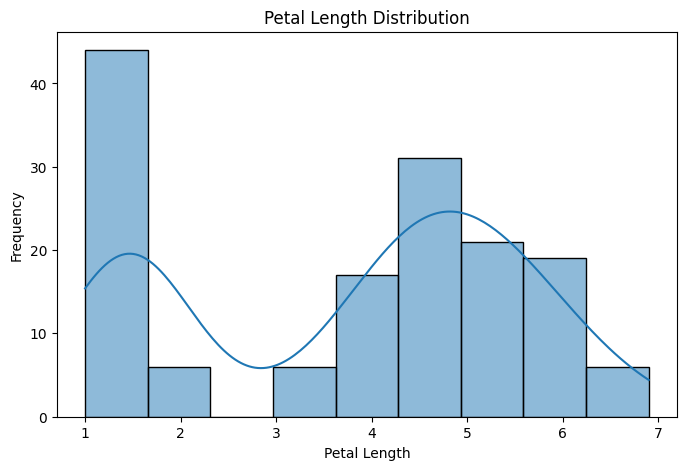

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="petal_length",
    kde=True
)

plt.title("Petal Length Distribution")
plt.xlabel("Petal Length")
plt.ylabel("Frequency")

plt.show()

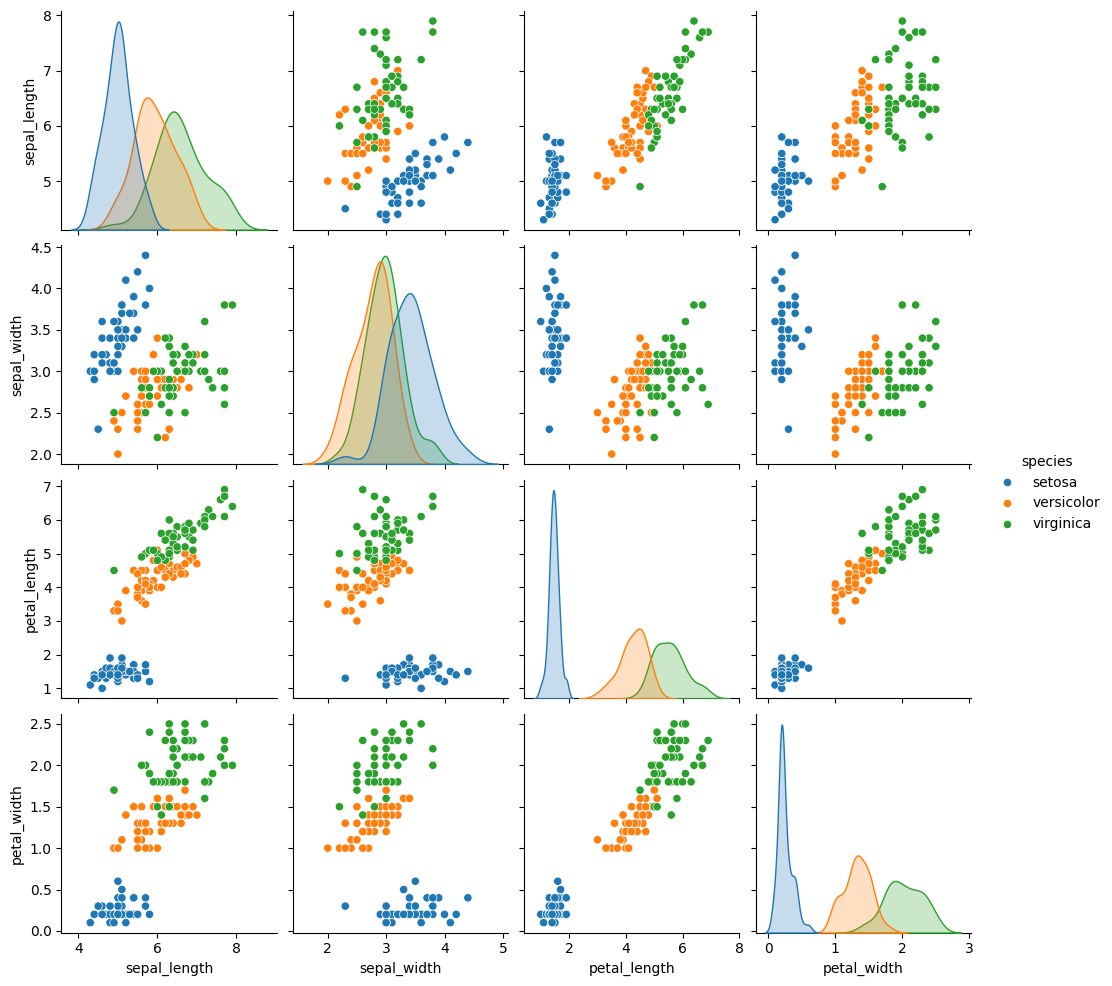

In [13]:
sns.pairplot(
    df,
    hue="species"
)

plt.show()

In [14]:
print(df.isnull().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [15]:
X = df.drop("species", axis=1)

y = df["species"]

In [16]:
print("Input Features:")
print(X.head())

print("Target:")
print(y.head())

Input Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
Target:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
print("X_train shape:", X_train.shape)

print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)

print("y_test shape:", y_test.shape)

X_train shape: (120, 4)
X_test shape: (30, 4)
y_train shape: (120,)
y_test shape: (30,)


In [19]:
print("Training Data:")
print(y_train.value_counts())

print("\nTesting Data:")
print(y_test.value_counts())

Training Data:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing Data:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
scaler = StandardScaler()

In [22]:
X_train_scaled = scaler.fit_transform(X_train)

In [23]:
X_test_scaled = scaler.transform(X_test)

In [24]:
print("Before Scaling:")
print(X_train.head())

Before Scaling:
     sepal_length  sepal_width  petal_length  petal_width
8             4.4          2.9           1.4          0.2
106           4.9          2.5           4.5          1.7
76            6.8          2.8           4.8          1.4
9             4.9          3.1           1.5          0.1
89            5.5          2.5           4.0          1.3


In [25]:
print("After Scaling:")
print(X_train_scaled[:5])

After Scaling:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


In [26]:
print("Mean:")
print(X_train_scaled.mean(axis=0))

print("Standard Deviation:")
print(X_train_scaled.std(axis=0))

Mean:
[-1.36927506e-16  9.99200722e-16  1.66533454e-17  1.70234197e-16]
Standard Deviation:
[1. 1. 1. 1.]


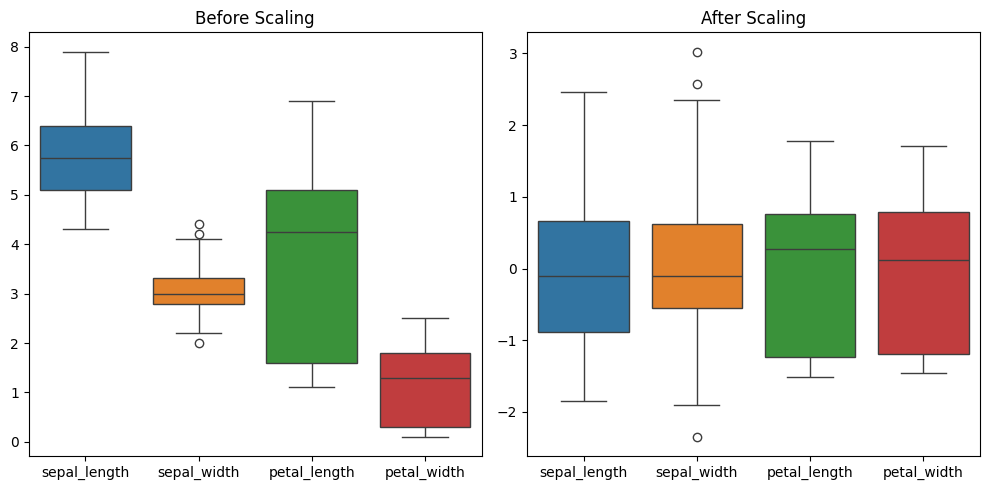

In [27]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=X_train)
plt.title("Before Scaling")

plt.subplot(1, 2, 2)
sns.boxplot(data=pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
))
plt.title("After Scaling")

plt.tight_layout()
plt.show()

In [28]:
from sklearn.linear_model import LogisticRegression

In [29]:
model_lr = LogisticRegression(
    max_iter=1000,
    tol=0.0001,
    random_state=42
)

In [30]:
model_lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [31]:
y_pred_lr = model_lr.predict(X_test_scaled)

print(y_pred_lr)

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [32]:
from sklearn.metrics import accuracy_score

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:",
      accuracy_lr * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


In [33]:
print("Iterations Used:")
print(model_lr.n_iter_)

Iterations Used:
[16]


In [34]:
from sklearn.tree import DecisionTreeClassifier

In [35]:
model_dt = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

In [36]:
model_dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [37]:
y_pred_dt = model_dt.predict(X_test)

In [38]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:",
      accuracy_dt * 100, "%")

Decision Tree Accuracy: 96.66666666666667 %


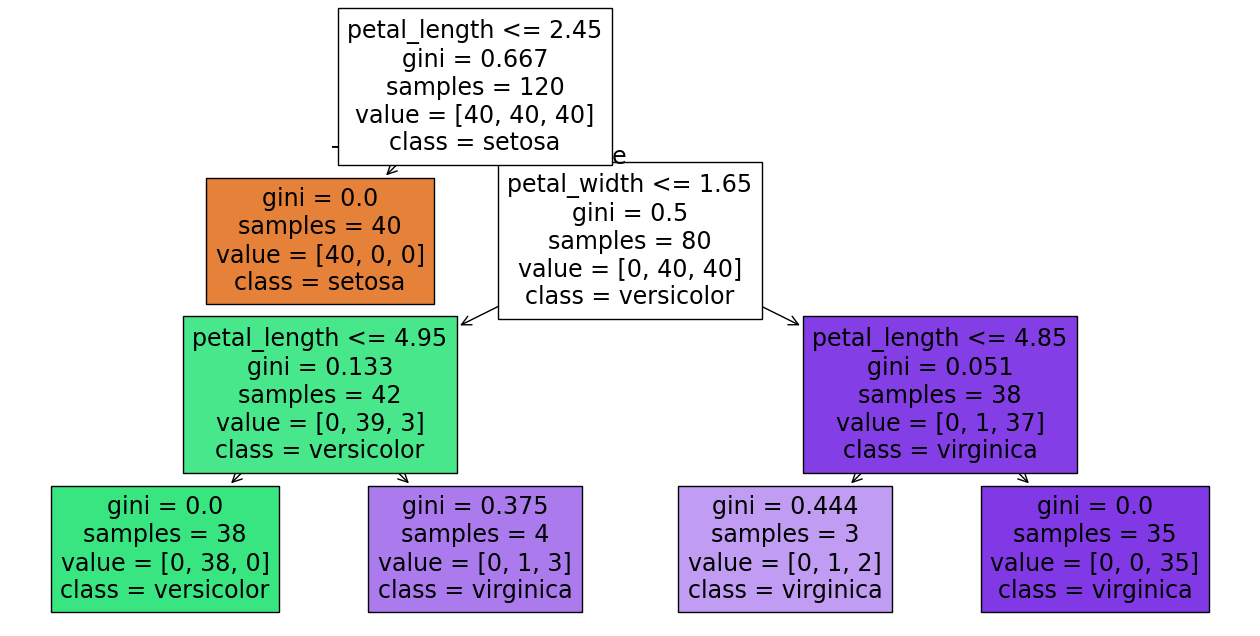

In [39]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    model_dt,
    feature_names=X.columns,
    class_names=model_dt.classes_,
    filled=True
)

plt.show()

In [40]:
print("Logistic Regression:",
      accuracy_lr * 100, "%")

print("Decision Tree:",
      accuracy_dt * 100, "%")

Logistic Regression: 93.33333333333333 %
Decision Tree: 96.66666666666667 %


In [41]:
from sklearn.metrics import classification_report

In [42]:
print("Logistic Regression Report")

print(classification_report(
    y_test,
    y_pred_lr
))

Logistic Regression Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [43]:
print("Decision Tree Report")

print(classification_report(
    y_test,
    y_pred_dt
))

Decision Tree Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [44]:
from sklearn.metrics import confusion_matrix

In [45]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

print(cm_lr)

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


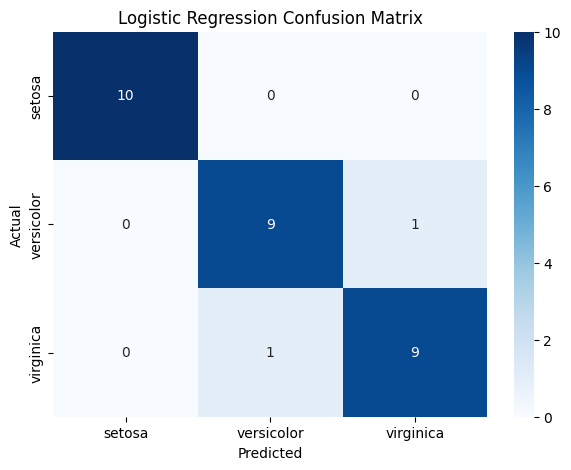

In [46]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model_lr.classes_,
    yticklabels=model_lr.classes_
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

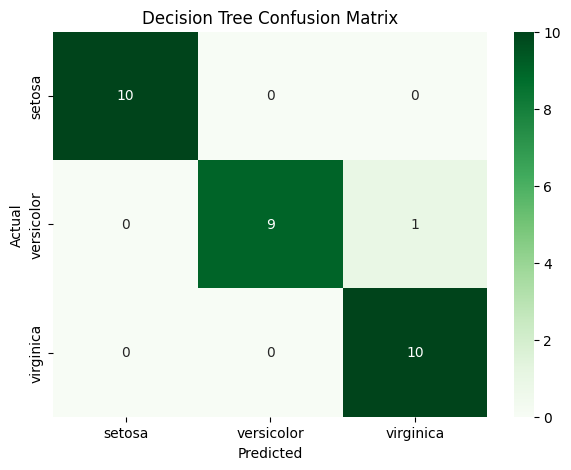

In [47]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=model_dt.classes_,
    yticklabels=model_dt.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

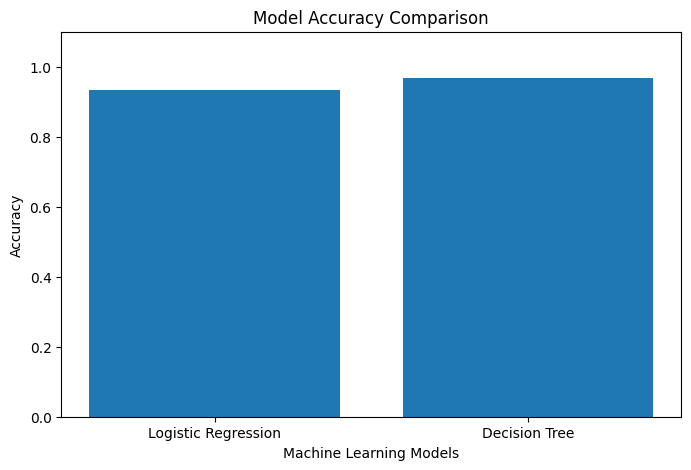

In [48]:
models = [
    "Logistic Regression",
    "Decision Tree"
]

accuracies = [
    accuracy_lr,
    accuracy_dt
]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1.1)

plt.show()

In [49]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

results = {
    "Model": ["Logistic Regression", "Decision Tree"],

    "Accuracy": [
        accuracy_lr,
        accuracy_dt
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr, average="macro"),
        precision_score(y_test, y_pred_dt, average="macro")
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr, average="macro"),
        recall_score(y_test, y_pred_dt, average="macro")
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr, average="macro"),
        f1_score(y_test, y_pred_dt, average="macro")
    ]
}

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9333     0.9333  0.9333    0.9333
1        Decision Tree    0.9667     0.9697  0.9667    0.9666


In [50]:
X_2d = df[["petal_length", "petal_width"]]

y_2d = df["species"]

print(X_2d.head())

print(y_2d.head())

   petal_length  petal_width
0           1.4          0.2
1           1.4          0.2
2           1.3          0.2
3           1.5          0.2
4           1.4          0.2
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [51]:
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

In [52]:
scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

X_test_2d_scaled = scaler_2d.transform(X_test_2d)

In [53]:
lr_2d = LogisticRegression(max_iter=1000)

lr_2d.fit(X_train_2d_scaled, y_train_2d)

LogisticRegression(max_iter=1000)

In [54]:
dt_2d = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

dt_2d.fit(X_train_2d, y_train_2d)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [55]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train_2d)
y_test_encoded = encoder.transform(y_test_2d)

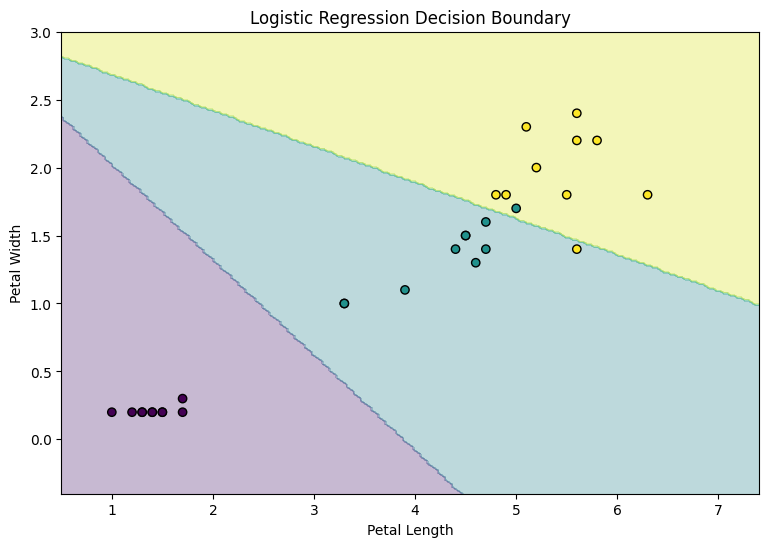

In [56]:
# Create grid points
x_min, x_max = X_2d["petal_length"].min() - 0.5, X_2d["petal_length"].max() + 0.5

y_min, y_max = X_2d["petal_width"].min() - 0.5, X_2d["petal_width"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Prepare grid data
grid = pd.DataFrame({
    "petal_length": xx.ravel(),
    "petal_width": yy.ravel()
})

# Scale grid data
grid_scaled = scaler_2d.transform(grid)

# Predict classes
Z = lr_2d.predict(grid_scaled)

Z = encoder.transform(Z)

Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

plt.scatter(
    X_test_2d["petal_length"],
    X_test_2d["petal_width"],
    c=y_test_encoded,
    cmap="viridis",
    edgecolors="black"
)

plt.title("Logistic Regression Decision Boundary")

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.show()

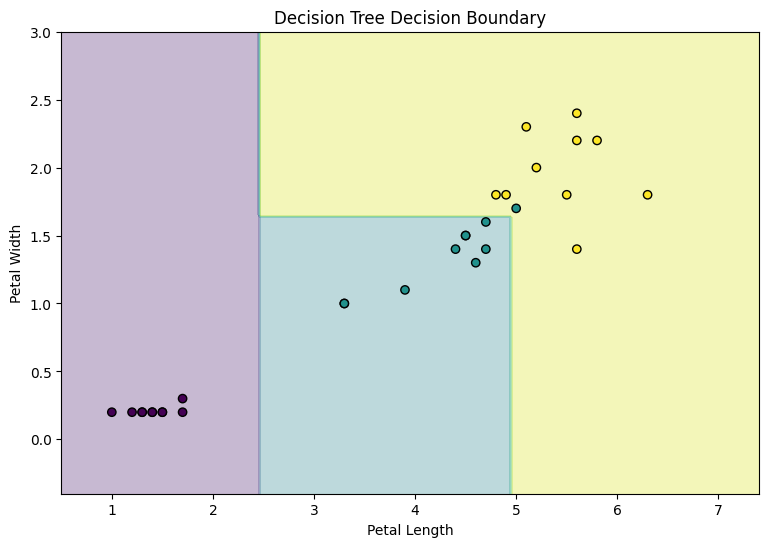

In [57]:
# Predict classes for grid
Z_dt = dt_2d.predict(grid)

Z_dt = encoder.transform(Z_dt)

Z_dt = Z_dt.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z_dt, alpha=0.3, cmap="viridis")

plt.scatter(
    X_test_2d["petal_length"],
    X_test_2d["petal_width"],
    c=y_test_encoded,
    cmap="viridis",
    edgecolors="black"
)

plt.title("Decision Tree Decision Boundary")

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.show()

In [58]:
from sklearn.model_selection import GridSearchCV

In [59]:
dt_parameters = {
    "max_depth": [2, 3, 4, 5, 6],
    "min_samples_split": [2, 4, 6],
    "criterion": ["gini", "entropy"]
}

In [60]:
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_parameters,
    cv=5,
    scoring="accuracy"
)

In [61]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 3, 4, 5, 6],
                         'min_samples_split': [2, 4, 6]},
             scoring='accuracy')

In [62]:
print("Best Parameters:")

print(grid_search.best_params_)

print("Best Cross Validation Accuracy:")

print(grid_search.best_score_)

Best Parameters:
{'criterion': 'gini', 'max_depth': 4, 'min_samples_split': 2}
Best Cross Validation Accuracy:
0.9416666666666668


In [63]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)

best_accuracy = accuracy_score(y_test, y_pred_best)

print("Optimized Decision Tree Accuracy:",
      best_accuracy * 100, "%")

Optimized Decision Tree Accuracy: 93.33333333333333 %


In [64]:
import os

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("figures", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [65]:
results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

print("Model comparison saved!")

Model comparison saved!


In [66]:
pd.DataFrame(cm_lr).to_csv(
    "results/logistic_confusion_matrix.csv",
    index=False
)

pd.DataFrame(cm_dt).to_csv(
    "results/decision_tree_confusion_matrix.csv",
    index=False
)

In [67]:
import joblib

joblib.dump(
    model_lr,
    "models/logistic_regression.pkl"
)

joblib.dump(
    model_dt,
    "models/decision_tree.pkl"
)

print("Models saved successfully!")

Models saved successfully!


In [68]:
plt.savefig(
    "figures/logistic_decision_boundary.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [69]:
plt.savefig(
    "figures/decision_tree_decision_boundary.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [70]:
import os

# Create main project folders

os.makedirs("Iris-Classification-Project/data", exist_ok=True)

os.makedirs("Iris-Classification-Project/figures", exist_ok=True)

os.makedirs("Iris-Classification-Project/models", exist_ok=True)

os.makedirs("Iris-Classification-Project/results", exist_ok=True)

print("All project folders created successfully!")

All project folders created successfully!


In [71]:
import shutil

shutil.copy(
    "iris_data.xlsx",
    "Iris-Classification-Project/data/iris_data.xlsx"
)

print("Dataset copied successfully!")

Dataset copied successfully!


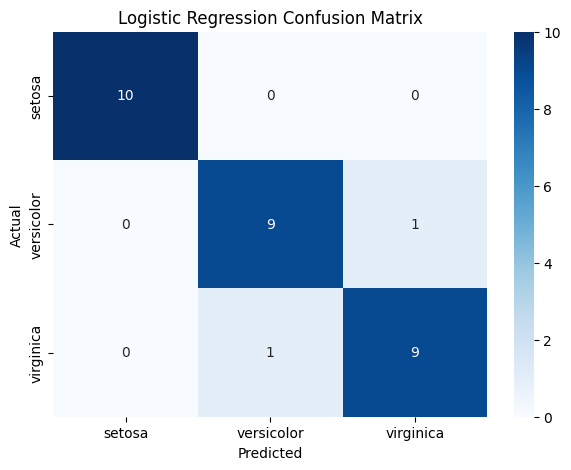

In [72]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model_lr.classes_,
    yticklabels=model_lr.classes_
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    "Iris-Classification-Project/figures/logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

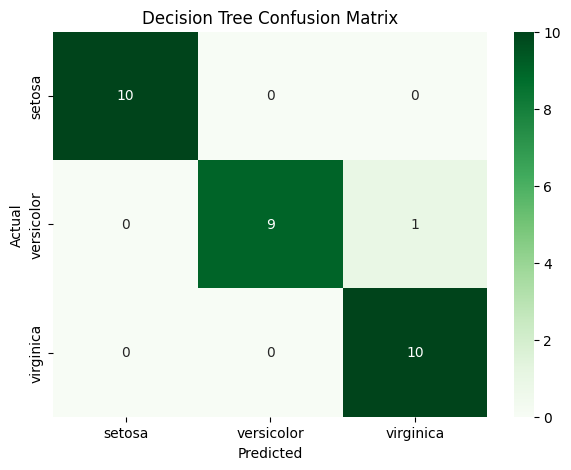

In [73]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=model_dt.classes_,
    yticklabels=model_dt.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    "Iris-Classification-Project/figures/decision_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [74]:
"Iris-Classification-Project/figures/logistic_decision_boundary.png"

'Iris-Classification-Project/figures/logistic_decision_boundary.png'

In [75]:
"Iris-Classification-Project/figures/decision_tree_decision_boundary.png"

'Iris-Classification-Project/figures/decision_tree_decision_boundary.png'

In [76]:
import joblib

joblib.dump(
    model_lr,
    "Iris-Classification-Project/models/logistic_regression.pkl"
)

joblib.dump(
    model_dt,
    "Iris-Classification-Project/models/decision_tree.pkl"
)

print("Both models saved successfully!")

Both models saved successfully!


In [77]:
results_df.to_csv(
    "Iris-Classification-Project/results/model_comparison.csv",
    index=False
)

pd.DataFrame(cm_lr).to_csv(
    "Iris-Classification-Project/results/logistic_confusion_matrix.csv",
    index=False
)

pd.DataFrame(cm_dt).to_csv(
    "Iris-Classification-Project/results/decision_tree_confusion_matrix.csv",
    index=False
)

print("All evaluation results saved!")

All evaluation results saved!


In [78]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
openpyxl
joblib
"""

with open(
    "Iris-Classification-Project/requirements.txt",
    "w"
) as file:

    file.write(requirements)

print("requirements.txt created!")

requirements.txt created!


In [79]:
gitignore_content = """
__pycache__/
.ipynb_checkpoints/
.venv/
*.pyc
.DS_Store
"""

with open(
    "Iris-Classification-Project/.gitignore",
    "w"
) as file:

    file.write(gitignore_content)

print(".gitignore created!")

.gitignore created!


In [80]:
for root, dirs, files in os.walk("Iris-Classification-Project"):

    print("\nFolder:", root)

    for file in files:

        print("   ", file)


Folder: Iris-Classification-Project
    requirements.txt
    .gitignore

Folder: Iris-Classification-Project/models
    decision_tree.pkl
    logistic_regression.pkl

Folder: Iris-Classification-Project/data
    iris_data.xlsx

Folder: Iris-Classification-Project/results
    model_comparison.csv
    decision_tree_confusion_matrix.csv
    logistic_confusion_matrix.csv

Folder: Iris-Classification-Project/figures
    decision_tree_confusion_matrix.png
    logistic_confusion_matrix.png


In [81]:
shutil.make_archive(
    "Iris-Classification-Project",
    "zip",
    root_dir=".",
    base_dir="Iris-Classification-Project"
)

print("Project ZIP created successfully!")

Project ZIP created successfully!


In [82]:
from google.colab import files

files.download("Iris-Classification-Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>